# KION: рекомендации на ручных признаках

Первая часть исследовательского задания. Полный эксперимент выполнен локально: валидационная сетка, фиксация параметров, два итоговых переобучения и отложенная тестовая оценка.

Этот ноутбук **использует реальные сохранённые модели**, проверяет их прогнозы и показывает все этапы. Повторное дорогое обучение не запускается автоматически. Команда полного воспроизведения приведена в конце; детали — в `REPORT.md`.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "config.toml").exists())
sys.path.insert(0, str(ROOT))
from kion.config import Config
cfg = Config.load(ROOT / "config.toml")
for key in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"]:
    os.environ[key] = str(cfg.threads)
import numpy as np
import pandas as pd
import pyarrow as pa
pa.set_cpu_count(cfg.threads); pa.set_io_thread_count(cfg.threads)
from IPython.display import display, Image, Markdown
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 30)
pd.set_option("display.precision", 5)
RESULTS = cfg.path("results_dir")
def read_json(name):
    return json.loads((RESULTS / name).read_text())
print("Python:", sys.version.split()[0], "| CPU threads:", cfg.threads)

Python: 3.14.7 | CPU threads: 2


## Источник и выборка

Использован полный `data_original.zip` фиксированного коммита KION. Это записи **о последних просмотрах пар**, не полный журнал повторных событий. Из случайных 100 000 пользователей сохранена вся доступная история, без сэмплирования отдельных строк. Даты берутся из самих данных.

In [2]:
from kion.protocol import load_prepared, make_snapshot, day_number
from kion.io import sha256
sample = read_json("sample_manifest.json")
audit = read_json("data_audit.json")
events, users, items = load_prepared(cfg)  # SHA-256 всех исходных таблиц проверяется внутри
assert len(events) == sample["sample_rows"]
assert events.user_id.nunique() == sample["sample_users"]
display(pd.DataFrame([
    {"набор": "Полный архив", "пользователей": audit["users"], "строк": audit["rows"]},
    {"набор": "Выборка", "пользователей": events.user_id.nunique(), "строк": len(events)},
]))
print("Даты:", audit["min_date"], "—", audit["max_date"])
print("SHA-256 архива:", sample["archive_sha256"])
display(events.head())

,набор,пользователей,строк
0,Полный архив,962179,5476251
1,Выборка,100000,572621


Даты: 2021-03-13 — 2021-08-22
SHA-256 архива: 50fc5b7db78cbda4c3d0ee5bb5bea4c416cff41e8af58aab0b661d0d3e9dfa9b


,user_id,item_id,last_watch_dt,total_dur,watched_pct,day
0,0,12192,2021-07-16,89.0,0.0,18824
1,0,7102,2021-07-19,169.0,3.0,18827
2,0,9728,2021-07-19,4.0,0.0,18827
3,0,14359,2021-07-19,130.0,2.0,18827
4,0,15297,2021-07-19,459.0,0.0,18827


## Задача, время и фиксация до теста

Top-10 фильмов, ещё не наблюдавшихся в доступной истории; позитив — записанная пара в следующие 7 дней. Label 0 не означает отказ после показа. Оцениваются пользователи с историей и будущими целями; cold-start и удержание всей базы этим числом не описываются.

Каждый срез использует только прошлые строки. После выбора параметров валидационный срез включён в итоговое обучение. Число деревьев фиксировано; тест не передавался как `eval_set`.

In [3]:
from kion.final import load_protocol
protocol, frozen = load_protocol(cfg)
assert frozen["selection_split"] == "validation" and not frozen["test_evaluated"]
assert cfg.test_cutoff not in protocol["training_cutoffs"]
display(pd.DataFrame([
    {"срез": cutoff, "конец labels (не включён)": str(pd.Timestamp(cutoff) + pd.Timedelta(days=cfg.horizon_days))[:10],
     "роль": "train/refit" if cutoff != cfg.test_cutoff else "held-out test"}
    for cutoff in protocol["training_cutoffs"] + [cfg.test_cutoff]
]))
display(pd.Series(frozen["parameters"], name="Параметры зафиксированы до теста"))
print("Зафиксированный контроль:", protocol["reference_method"])
print("Фиксация UTC:", protocol["locked_at_utc"])

,срез,конец labels (не включён),роль
0,2021-07-19,2021-07-26,train/refit
1,2021-07-26,2021-08-02,train/refit
2,2021-08-02,2021-08-09,train/refit
3,2021-08-09,2021-08-16,train/refit
4,2021-08-16,2021-08-23,held-out test


loss_function         YetiRank
depth                        8
l2_leaf_reg                  3
iterations                 299
learning_rate             0.05
random_seed                 42
thread_count                 2
max_ctr_complexity           1
Name: Параметры зафиксированы до теста, dtype: object

Зафиксированный контроль: popularity_7d
Фиксация UTC: 2026-10-24T11:57:58.709181+00:00


## Исторические признаки и кандидаты

Четыре источника: популярность всей истории, популярность за 7 дней, ItemKNN, жанровый профиль. До 100 от источника, первые 10 каждого сохраняются, затем RRF до 200; прошлые пары исключены. Позитивы из будущего в пул не вставляются.

82 признака: статистики пользователя и фильма за 7/30/90 дней и всю историю, давность, тренды, категории и косвенные связи с жанрами, режиссёрами, типом контента, а также баллы источников. Средняя длительность считается после log1p. Подробные определения — в `results/FEATURES.md`.

In [4]:
from kion.features import FeatureStore
from kion.candidates import CandidateRetriever
from kion.dataset import label_pairs
snapshot = make_snapshot(events, cfg.test_cutoff, cfg.horizon_days)
store = FeatureStore(snapshot, users, items, cfg)
assert store.history.day.max() < day_number(cfg.test_cutoff)
demo_user = min(snapshot.targets)
pairs = CandidateRetriever(store, cfg).generate([demo_user])
features = store.transform(pairs)
assert "label" not in features.columns
seen = set(snapshot.history.loc[snapshot.history.user_id == demo_user, "item_id"])
assert not seen.intersection(pairs.item_id)
print("Пользователь:", demo_user, "| кандидатов:", len(pairs), "| максимальная дата истории:", store.history.last_watch_dt.max())
display(features[["user_id", "item_id", "u_count_7", "i_count_7", "pair_genre_share_all", "cand_knn_score"]].head(10))
# Только после расчёта признаков присоединяем будущие labels для анализа.
example_labels = label_pairs(pairs, snapshot.targets)
print("Позитивов в пуле:", int(example_labels.sum()), "| всего будущих целей:", len(snapshot.targets[demo_user]))

Пользователь: 153 | кандидатов: 200 | максимальная дата истории: 2021-08-15 00:00:00


,user_id,item_id,u_count_7,i_count_7,pair_genre_share_all,cand_knn_score
0,153,14,1.0,65.0,0.50000,0.10473
1,153,24,1.0,13.0,0.16667,0.00000
2,153,101,1.0,113.0,0.25000,0.06760
3,153,142,1.0,253.0,0.25000,0.22862
4,153,169,1.0,68.0,0.25000,0.00000
5,153,341,1.0,628.0,0.00000,0.07625
6,153,475,1.0,10.0,0.50000,0.00000
7,153,512,1.0,397.0,0.00000,0.00000
8,153,517,1.0,27.0,0.50000,0.00000
9,153,657,1.0,28.0,0.16667,0.00000


Позитивов в пуле: 2 | всего будущих целей: 2


## Валидация и выбор модели

Сетка depth={6,8}, l2={3,10}, не более 300 итераций. Конфигурация выбрана по внешней macro NDCG@10 с полным целевым списком. Внутренняя NDCG CatBoost нормирована в кандидатах и даёт 1 группам без позитивов; она используется для выбора числа деревьев и не заменяет внешнюю оценку.

Первая конфигурация использовала проверенный префикс ранней длинной модели. Поздние итерации исключены из выбора; исходная модель не участвовала в тесте. `execution_kind` и `prior_source_seconds` разделяют перенос префикса и обучение с нуля.

,name,depth,l2_leaf_reg,iterations,ndcg@10,seconds,execution_kind,prior_source_seconds
0,depth6_l23,6,3,288,0.15367,1.10353,verified_prefix,1961.12201
1,depth6_l210,6,10,298,0.15007,801.82201,fresh_fit,0.00000
2,depth8_l23,8,3,299,0.15379,898.39701,fresh_fit,0.00000
3,depth8_l210,8,10,299,0.15010,849.37169,fresh_fit,0.00000


,method,ndcg@10,recall@10,map@10,candidate_recall@200,users
0,popularity_all,0.11659,0.16893,0.08154,0.53975,10852
1,popularity_7d,0.13089,0.20122,0.08856,0.53975,10852
2,itemknn,0.12746,0.18693,0.08806,0.53975,10852
3,rrf,0.10988,0.17848,0.07062,0.53975,10852
4,catboost,0.15379,0.22415,0.10759,0.53975,10852
5,catboost_without_personal_features,0.13705,0.20264,0.09548,0.53975,10852


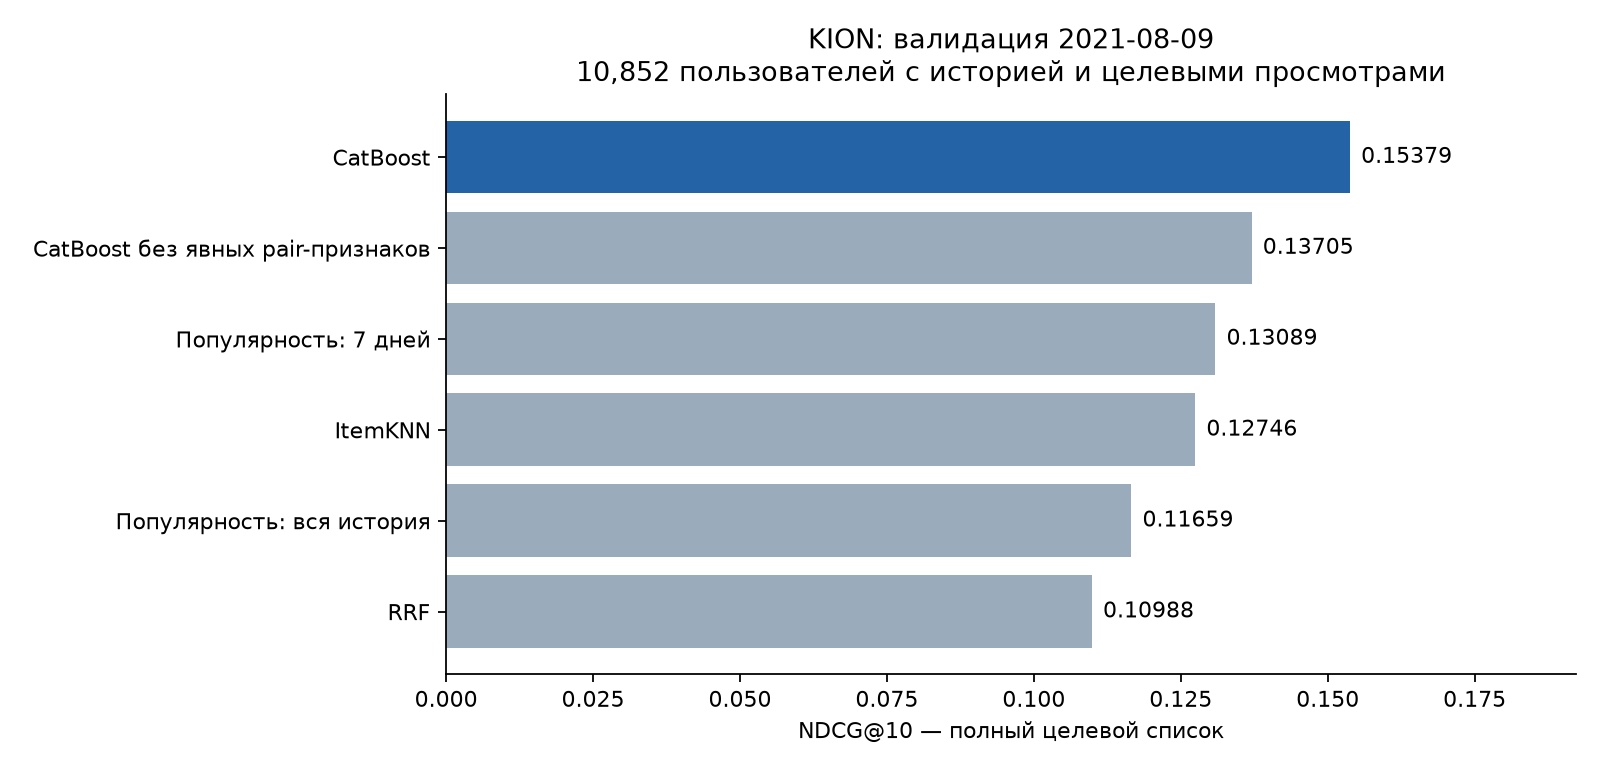

In [5]:
grid = pd.read_csv(RESULTS / "grid_results.csv")
validation = pd.read_csv(RESULTS / "validation_results.csv")
display(grid[["name", "depth", "l2_leaf_reg", "iterations", "ndcg@10", "seconds", "execution_kind", "prior_source_seconds"]])
display(validation)
display(Image(filename=str(RESULTS / "validation_ndcg.png")))

## Итоговое переобучение

Полная модель и абляция обучены на четырёх срезах: до 5000 warm-active пользователей на срез, без групп с нулём найденных позитивов **только в обучении**. Вся когорта используется для исторических статистик.

Следующая ячейка вызывает итоговый pipeline. Для завершённого запуска он проверяет сохранённые артефакты и возвращает их без повторного обучения. Реальные замеры обучения показаны в таблице.

In [6]:
from kion.final import run_final, verify_final
run = run_final(cfg)
assert run["test_evaluated"] and run["parameters"] == frozen["parameters"]
receipts = pd.DataFrame([
    {"модель": name, "пар": receipt["training_rows"], "групп": receipt["training_queries"],
     "признаков": len(receipt["identity"]["features"]), "деревьев": receipt["tree_count"],
     "время, с": receipt["seconds"], "test labels в fit": receipt["test_labels_used"],
     "early stopping": receipt["early_stopping"]}
    for name, receipt in run["models"].items()
])
display(receipts)
assert not receipts["test labels в fit"].any() and not receipts["early stopping"].any()

Final test already completed; using immutable results, no refitting


,модель,пар,групп,признаков,деревьев,"время, с",test labels в fit,early stopping
0,catboost,2940779,14704,82,299,1049.38066,False,False
1,catboost_without_personal_features,2940779,14704,45,299,1178.10272,False,False


## Проверка загрузки

Загружаем обе модели с диска, заново скорим тестовых кандидатов и проверяем совпадение каждого балла и агрегированных метрик с сохранённой оценкой. Это проверка воспроизводимости, параметры при ней не меняются.

In [7]:
verification = verify_final(cfg)
assert verification["verified"]
display(pd.Series(verification["metrics"], name="Метрики после загрузки"))
print("Допуск:", verification["tolerance"])
print("SHA-256 модели:", verification["model_sha256"])

ndcg@10                     0.15729
recall@10                   0.23151
map@10                      0.10896
candidate_recall@200        0.54367
users                   11425.00000
Name: Метрики после загрузки, dtype: float64

Допуск: 1e-10
SHA-256 модели: 3ab83aaba1472ba6f2e8aaffc11e8dbe35be88e8f14a2016b981c742873e5d5c


## Независимый тест и доверительные интервалы

Все методы ранжируют одинаковых кандидатов; пропуски и новые фильмы остаются в знаменателях. Метрики — средние по пользователям. MAP@10 делится на min(10, число целей). Ничьи разрешаются по ID фильма.

Bootstrap: 1000 выборок пользователей с возвращением, seed 42, percentile 95%. Парное сравнение использует одних и тех же пользователей; первичный контроль выбран на валидации. Модели фиксированы: это не интервалы переобучения, других временных периодов или онлайн-эффекта. Вторичные сравнения не скорректированы на множественность.

In [8]:
test = pd.read_csv(RESULTS / "test_results.csv")
intervals = read_json("test_confidence_intervals.json")
display(test[["method", "ndcg@10", "ndcg@10_lower", "ndcg@10_upper", "recall@10", "map@10", "candidate_recall@200"]])
paired = pd.DataFrame([
    {"CatBoost минус": method, **values["ndcg@10"]}
    for method, values in intervals["paired_catboost_minus"].items()
])
display(paired)
print("Первичное сравнение:", intervals["reference_selected_on_validation"])

,method,ndcg@10,ndcg@10_lower,ndcg@10_upper,recall@10,map@10,candidate_recall@200
0,popularity_all,0.11567,0.11173,0.11982,0.16447,0.08128,0.54367
1,popularity_7d,0.13656,0.13203,0.14103,0.21561,0.09080,0.54367
2,itemknn,0.12439,0.12064,0.12870,0.18570,0.08396,0.54367
3,rrf,0.11182,0.10782,0.11559,0.18008,0.07170,0.54367
4,catboost,0.15729,0.15258,0.16196,0.23151,0.10896,0.54367
5,catboost_without_personal_features,0.14334,0.13893,0.14791,0.21687,0.09834,0.54367


,CatBoost минус,mean,lower,upper
0,popularity_all,0.04162,0.03845,0.04463
1,popularity_7d,0.02074,0.01804,0.02356
2,itemknn,0.03290,0.03006,0.03561
3,rrf,0.04548,0.04239,0.04881
4,catboost_without_personal_features,0.01396,0.01158,0.01669


Первичное сравнение: popularity_7d


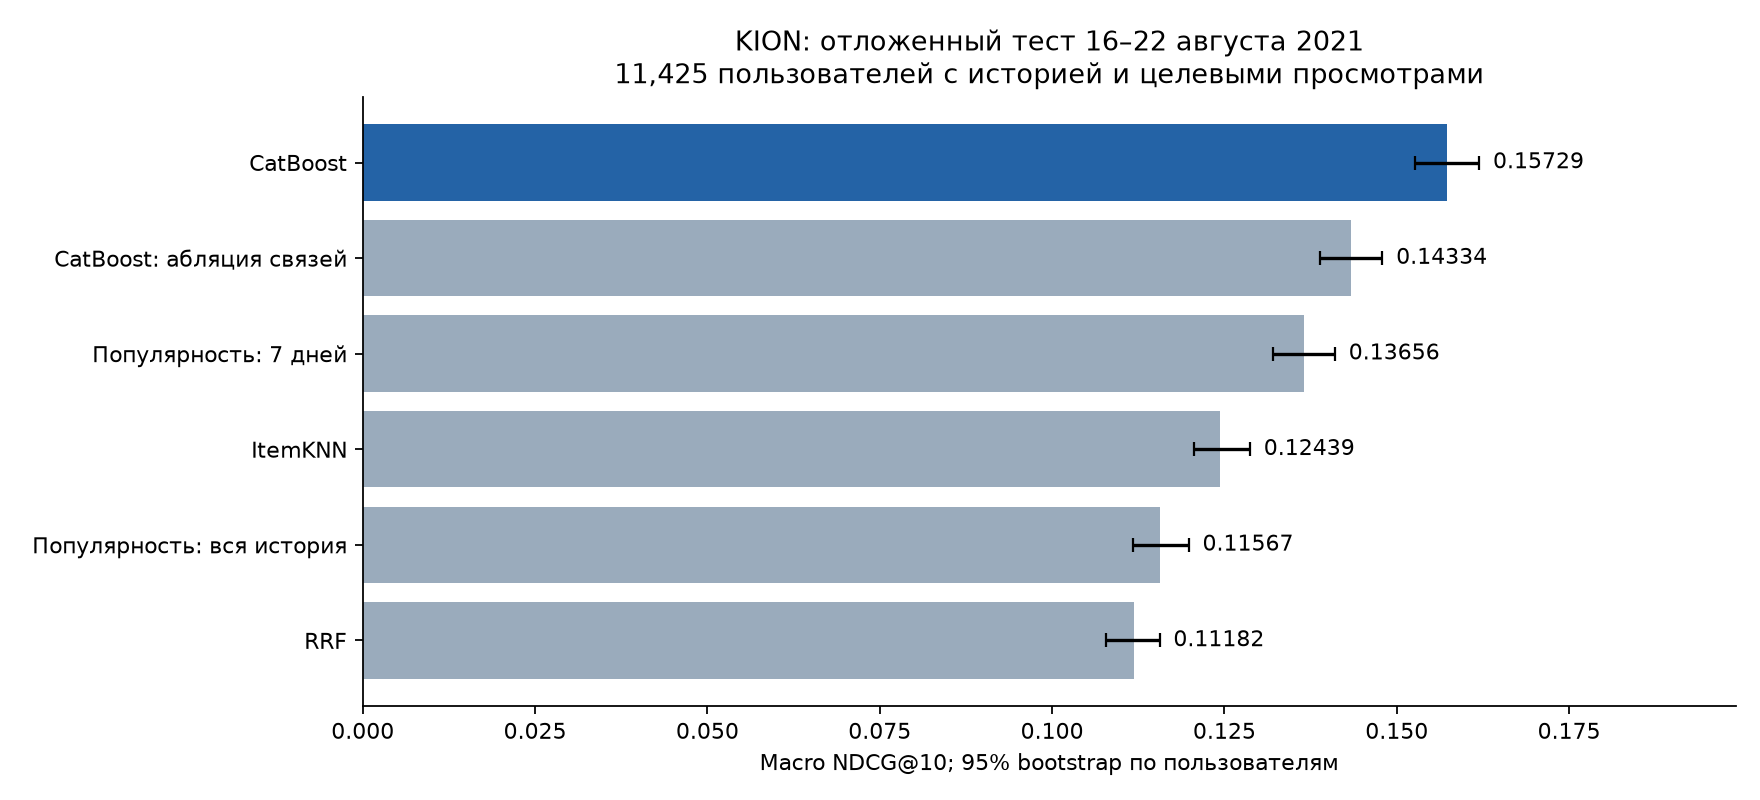

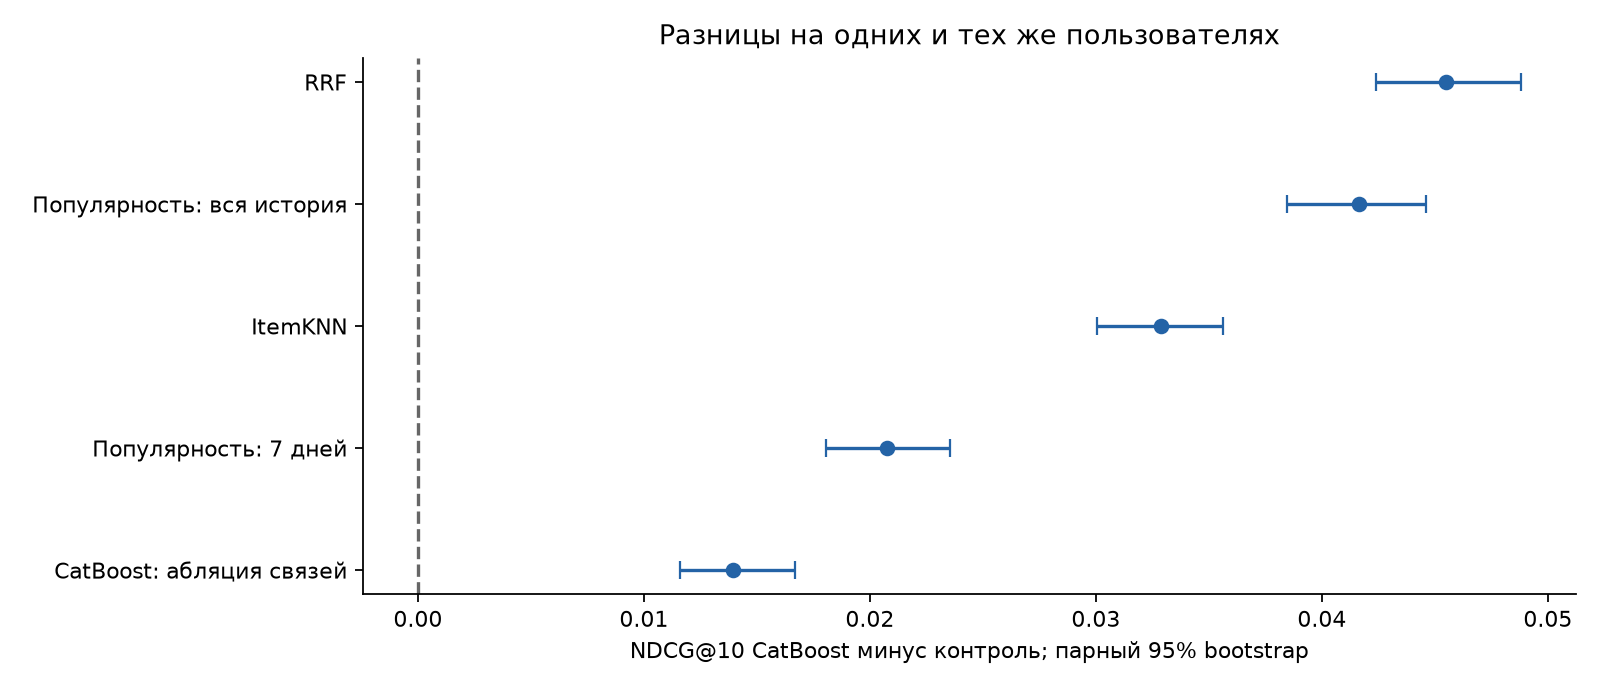

In [9]:
display(Image(filename=str(RESULTS / "test_metrics.png")))
display(Image(filename=str(RESULTS / "test_paired_differences.png")))

## Абляция и ошибки извлечения кандидатов

В абляции удалены pair_*, cand_knn_*, cand_genre_* и rrf_score. Сохраняются пользовательские/объектные характеристики и персональный пул; это не полное отключение персонализации.

Покажем группы по длине истории и верхнюю границу качества при идеальном порядке имеющихся кандидатов. Oracle не является обученной моделью.

In [10]:
segments = pd.read_csv(RESULTS / "test_segments.csv")
selected = segments[segments["method"].isin(["catboost", run["reference_method"], "catboost_without_personal_features"])]
display(selected[["segment", "method", "users", "ndcg@10", "recall@10"]])
from scripts.build_report import oracle_ndcg
per_user = pd.read_parquet(ROOT / run["artifact_directory"] / "catboost_per_user.parquet")
print("Без единого позитивного кандидата:", int((per_user["candidate_recall@200"] == 0).sum()), "из", len(per_user))
print("Oracle NDCG@10 на этом пуле:", round(oracle_ndcg(per_user), 5))

,segment,method,users,ndcg@10,recall@10
1,history_1_2,popularity_7d,2688,0.18085,0.28910
4,history_1_2,catboost,2688,0.19986,0.30341
5,history_1_2,catboost_without_personal_features,2688,0.19093,0.29168
7,history_3_9,popularity_7d,4321,0.14584,0.23535
10,history_3_9,catboost,4321,0.16945,0.25110
11,history_3_9,catboost_without_personal_features,4321,0.15396,0.23521
13,history_10_plus,popularity_7d,4416,0.10052,0.15158
16,history_10_plus,catboost,4416,0.11949,0.16859
17,history_10_plus,catboost_without_personal_features,4416,0.10398,0.15340
19,retrieval_zero_hits,popularity_7d,3123,0.00000,0.00000


Без единого позитивного кандидата: 3123 из 11425
Oracle NDCG@10 на этом пуле: 0.59105


## Признаки и стоимость

PredictionValuesChange описывает изменение предсказаний, не причинный эффект. Коррелирующие признаки делят важность. Общий эффект удалённой группы оценивается отдельной абляцией, а не суммой этих чисел.

In [11]:
importance = pd.read_csv(RESULTS / "final_feature_importance.csv")
display(importance.head(15))
print("Время финального запуска, мин:", round(run["elapsed_seconds"] / 60, 2))
print("Peak RSS, МиБ:", round(run["peak_rss_mb"], 1))
print("Контрольные суммы и версии:")
display(pd.Series(run["versions"]))

,feature,importance
0,cand_knn_score,16.45020
1,cand_knn_rank,13.98119
2,i_count_7,9.48956
3,cand_recent_score,6.89407
4,i_trend_7_30,5.94984
5,cand_recent_rank,5.57099
6,cand_pop_rank,3.63417
7,cand_pop_score,3.61528
8,i_count_all,2.83265
9,rrf_score,2.44753


Время финального запуска, мин: 37.61
Peak RSS, МиБ: 3982.8
Контрольные суммы и версии:


numpy        2.5.4
pandas       3.1.0
scipy       1.18.1
catboost    1.2.10
pyarrow     26.0.0
dtype: str

## Выдача рекомендаций

Используем итоговую модель на срезе 16 августа. Баллы задают порядок выдачи и не являются вероятностями просмотра.

In [12]:
from kion.inference import recommend_saved
recommendation = recommend_saved(cfg, demo_user, k=10, stage="test")
assert recommendation["as_of"] == cfg.test_cutoff
assert len(recommendation["item_ids"]) == len(set(recommendation["item_ids"]))
assert not seen.intersection(recommendation["item_ids"])
output = pd.DataFrame({"item_id": recommendation["item_ids"], "score": recommendation["scores"]})
display(output.merge(items[["item_id", "genres", "release_year"]], on="item_id", how="left"))

,item_id,score,genres,release_year
0,10440,3.52247,"триллеры, детективы",2021.0
1,4151,3.26569,комедии,2021.0
2,12192,2.63250,"драмы, детективы, комедии",2019.0
3,9728,2.47980,"боевики, триллеры",2021.0
4,16228,2.46298,триллеры,2021.0
5,13865,2.37254,"драмы, военные, приключения",2021.0
6,341,1.92393,телешоу,2021.0
7,3734,1.91146,комедии,2021.0
8,2657,1.81809,"драмы, триллеры",2021.0
9,142,1.65993,"драмы, триллеры",2020.0


## Ограничения и воспроизведение

Одна когорта и одна неделя не устанавливают качество на всей базе. Last-watch формат не восстанавливает историю повторных просмотров; неизвестные версии метаданных считаются статическими. Нет показов и истинных негативов; warm-active оценка не измеряет удержание и качество cold-start. Офлайн-прирост не равен причинному бизнес-эффекту.

Для второй части baseline фиксирован. Альтернатива выбирается по train/validation до её тестовой оценки и сравнивается на том же сохранённом тесте. Если тестовые результаты используются для итеративного выбора моделей, для независимого вывода понадобится новый holdout.

Полный повтор обучения, с отдельными результатами:

```bash
python -m scripts.reproduce --name reproduction --full
```

Проверка готовых моделей без обучения:

```bash
python main.py verify-test
python main.py recommend --user-id 17 --stage test
```

Команда ниже только печатает инструкцию. Переключатель нужен, чтобы обычное выполнение ноутбука не запускало повторно длительную CPU-сетку.

In [13]:
RETRAIN_FROM_SCRATCH = False
if RETRAIN_FROM_SCRATCH:
    import subprocess
    subprocess.run([sys.executable, "-m", "scripts.reproduce", "--name", "notebook_reproduction", "--full"], cwd=ROOT, check=True)
else:
    print("Полный эксперимент уже выполнен; дорогое обучение повторно не запускается.")
print("Проверено: реальные данные, кандидаты, фиксированные параметры, обе загруженные модели и тестовые прогнозы.")

Полный эксперимент уже выполнен; дорогое обучение повторно не запускается.
Проверено: реальные данные, кандидаты, фиксированные параметры, обе загруженные модели и тестовые прогнозы.
